In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

import pickle

from torch import Tensor
from torch.utils.data import DataLoader

from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor
from torchvision import transforms, datasets

import pytorch_lightning as pl

from tqdm.notebook import tqdm
from argparse import Namespace
from skimage.transform import resize
import matplotlib.pyplot as plt

from rietools_pt import *

from utils import AtariDataset, plot_disk, plot_recon

In [3]:
opts = {}
opts['dataset'] = 'bd'
opts['nw_type'] = 'mlp'
opts['input_dim'] = 50
if opts['dataset'] == 'nnlm':
    opts['input_dim'] = 128
    opts['nw_type'] = 'mlp'
if opts['dataset'] == 'fasta':
    opts['input_dim'] = 128
    opts['nw_type'] = 'mlp'
if opts['dataset'] == 'mnist':
    opts['input_dim'] = 784
    opts['nw_type'] = 'mlp'
    
opts['dim_z'] = 2
opts['lr_adam'] = 1e-3
opts['lr_rsgd'] = 1e-3
opts['batch_size'] = 64
opts['beta_mmd'] = 1.0
opts['sigma_mmd'] = 1.0 # Laplacian kernel width
opts['mmd_q'] = 1
opts['varregnorm'] = 2 # L1 or L2
opts['lambda_mmd'] = 1.0 # variance regularizer weight to avoid variance collapse
opts['beta_kld'] = 10.0
opts['hyp_c'] = 1.0
opts['c'] = 1.0
opts['use_expmap'] = False
opts['hyp_mu'] = True
opts['hyp_var'] = False
opts['scalar_dispersion'] = True
opts['init_std'] = 0.01
opts['use_bias'] = True
opts['init_bias'] = 0.0
opts['prior_var'] = 1.0
opts['reparam'] = 'hyp'
opts['b'] = 2
opts['treedepth'] = 6
opts['loss'] = 'l2' # l2 or bce loss
opts['recon_weight'] = 1.0
#opts['c'] = 5 # number of noise points per vertex
opts['dec_mlr'] = False
opts['enc_act_mu'] = torch.tanh #lambda x: tf.nn.leaky_relu(x,alpha=0.2)
opts['enc_act_sigma'] = None #tf.nn.tanh
opts['binarize'] = True
opts['nr_mmd_samples'] = 1 
opts['mmd_kernel'] = 'laplacian'

opt = Namespace(**opts)

In [4]:
class LitAutoEncoder(pl.LightningModule):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(28 * 28, 64), 
                                     nn.ReLU(), 
                                     nn.Linear(64, 3))
        self.decoder = nn.Sequential(nn.Linear(3, 64), 
                                     nn.ReLU(), 
                                     nn.Linear(64, 28 * 28))

    def training_step(self, batch, batch_idx):
        x, y = batch
        x = x.view(x.size(0), -1)
        z = self.encoder(x)
        x_hat = self.decoder(z)
        loss = F.mse_loss(x_hat, x)
        # Include extra logging here
        return loss
    
    def configure_optimizers(self):
        optimizer = optim.AdamW(self.parameters(), lr=0.001)
        return optimizer

In [7]:
class HypFFLayer(nn.Module):
    """ Hyperbolic FF Layer """
    def __init__(self, size_in, size_out, c=1.0, activation=None, init_bias='zeros'):
        super().__init__()
        self.size_in, self.size_out = size_in, size_out
        self.activation = activation
        self.c = c
        weights = torch.Tensor(size_out, size_in)
        self.weights = nn.Parameter(weights)  # nn.Parameter is a Tensor that's a module parameter.
        bias = torch.Tensor(size_out)
        self.bias = nn.Parameter(bias)

        # initialize weights and biases
        nn.init.kaiming_uniform_(self.weights, a=np.sqrt(5)) # weight init
        #nn.init.xavier_uniform_(self.weights)
        fan_in, _ = nn.init._calculate_fan_in_and_fan_out(self.weights)
        bound = 1 / np.sqrt(fan_in)
        if init_bias == 'uniform':
            nn.init.uniform_(self.bias, -bound, bound)  # bias init
        else:
            nn.init.zeros_(self.bias)  # bias init
        backward_hook = self.weights.register_hook(self.rsgd)
    
    def rsgd(self, grad):
        # modify gradients here
        #print("scaling gradients using Riemannian metric")
        rsgd_grad = grad*riemannian_gradient_c(grad,self.c)
        return rsgd_grad  # scaling the gradients by 0.1    
    
    def forward(self, x):
        c = self.c
        x = exp_map(x,c=self.c) + 1e-7
        Mx = torch.mm(x, self.weights.t())
        Mx_norm = torch.norm(Mx, 2, dim=1,keepdim=True)
        x_norm = torch.norm(x, 2, dim=1,keepdim=True)
        y = 1./np.sqrt(c)*tf_tanh(Mx_norm/x_norm*tf_atanh(np.sqrt(c)*x_norm))*Mx/Mx_norm
        y = project_hyp_vec(y,c)
        y = mobius_add(y,self.bias.unsqueeze(0),c)
        if self.activation is not None:
            # hyperbolic non-linearity
            y = exp_map(self.activation(log_map(y,c)),c)
        return y
    
    

class AtariCNN(nn.Module):
    # action conditioning?
    def __init__(self, opt, env, use_actions=False):
        super().__init__()
        ob_shapes = list(env.observation_space.shape)
        ac_shapes = list(env.action_space.shape)
        if not ac_shapes:
            ac_shapes = [1]

        if use_actions:
            ac_dim = ac_shapes[-1]
        else:
            ac_dim = 0

        self.obs_network = nn.Sequential(
            layer_init(nn.Conv2d(4, 32, 8, stride=4)),
            nn.ReLU(),
            layer_init(nn.Conv2d(32, 64, 4, stride=2)),
            nn.ReLU(),
            layer_init(nn.Conv2d(64, 64, 3, stride=1)),
            nn.ReLU())
            #nn.Flatten())
            
        self.obs_acs_network = nn.Sequential(
            layer_init(nn.Linear(64 * 7 * 7 + ac_dim, 512)),
            nn.ReLU(),
        )
        #self.critic = layer_init(nn.Linear(512, 1), std=1)

    def forward(self, ob, ac=None):
        if len(ob.shape) == 3:
            ob = ob.unsqueeze(0)

        ob_enc = self.obs_network(ob/255)
        ob_enc = ob_enc.reshape(ob_enc.shape[0], -1)
        if ac is not None:
            if len(ac.shape) == 0:
                ac = ac.unsqueeze(0).unsqueeze(0)
            elif len(ac.shape) == 1:
                ac = ac.unsqueeze(0)

            ob_enc = torch.cat([ob_enc, ac], dim=-1)
            x = self.obs_acs_network(ob_enc)
        else:
            x = self.obs_acs_network(ob_enc)
        
        return x


def atari_enc(dim_out=100,n_channels=1):
    encoder = nn.Sequential(
        nn.Conv2d(n_channels, 32, kernel_size=8, stride=4),
        nn.ReLU(),
        nn.Conv2d(32, 64, kernel_size=4, stride=3),
        nn.ReLU(),
        nn.Conv2d(64, 128, kernel_size=4, stride=2),
        nn.ReLU(),
        nn.Flatten(),
        nn.Linear(512,dim_out)
    )
    return encoder

def atari_dec(dim_in=100, n_channels=1):
    decoder = nn.Sequential(
        nn.Linear(dim_in, 512),
        nn.ReLU(),
        nn.Unflatten(1, (128,2,2)),
        nn.ConvTranspose2d(128, 64, kernel_size=4, stride=1),
        nn.ReLU(),
        nn.ConvTranspose2d(64, 32, kernel_size=4, stride=4),
        nn.ReLU(),
        nn.ConvTranspose2d(32,n_channels, kernel_size=8, stride=4),
        nn.Sigmoid()
    )
    return decoder

class AtariFrameAutoencoder(nn.Module):
    def __init__(self):
        super(AtariFrameAutoencoder, self).__init__()
        self.encoder = atari_enc()
        self.decoder = atari_dec()
        
    def forward(self, x):
        encoded = self.encoder(x)
        # enc shape / dec input shape: torch.Size([1, 128, 7, 7])
        decoded = self.decoder(encoded)

        return decoded

def is_any_nan(x):
    return torch.any(torch.isnan(x))

class PWA(pl.LightningModule):
    def __init__(self, opt):
        super().__init__()
        self.opt = opt
        dim_enc_out = 100
        if self.opt.dataset == 'mnist':
            self.encoder = nn.Sequential(nn.Linear(28 * 28, 64), 
                                         nn.ReLU(), 
                                         nn.Linear(64, dim_enc_out))
        elif self.opt.dataset == 'atari':
            self.encoder = atari_enc(dim_enc_out)
            
        if opt.hyp_mu:
            self.mu_encoder = HypFFLayer(dim_enc_out, opt.dim_z, activation=opt.enc_act_mu)
        else:
            self.mu_encoder = nn.Linear(dim_enc_out, opt.dim_z)
        
        if opt.scalar_dispersion:
            if self.opt.hyp_var:
                self.var_encoder = HypFFLayer(dim_enc_out,1, activation=opt.enc_act_sigma)
            else:
                self.var_encoder = nn.Linear(dim_enc_out, 1)
        elif opt.reparam == 'fullcov':
            if self.opt.hyp_var:
                self.var_encoder = HypFFLayer(dim_enc_out, opt.dim_z**2, activation=opt.enc_act_sigma)
            else:    
                self.var_encoder = nn.Linear(dim_enc_out, opt.dim_z**2 / 2) # cholesky factor
        else:
            if self.opt.hyp_var:
                self.var_encoder = HypFFLayer(dim_enc_out, opt.dim_z, name='sigma', activation=opt.enc_act_sigma)
            else:    
                self.var_encoder = nn.Linear(dim_enc_out, opt.dim_z)
        
        if self.opt.dataset == 'mnist':
            self.decoder = nn.Sequential(nn.Linear(opt.dim_z, 64), 
                                     nn.ReLU(), 
                                     nn.Linear(64, 28 * 28))
        elif self.opt.dataset == 'atari':
            self.decoder = atari_dec(opt.dim_z)


    def mmd_penalty(self, sample_pz, sample_qhat, sigma=None, q=1.0):
        # assert opts["e_noise"] in ('gaussian'), \
            # 'MMD++ works only with Gaussian encoders!'
        # Number of codes per the same pic
        opt = self.opt
        ns = opt.nr_mmd_samples
        n = opt.batch_size
        ls = opt.dim_z
        kernel = opt.mmd_kernel
        sigma2_p = 1 # opt.'pz_scale ** 2
        opt.pz = 'normal'

        sq_norms_pz, _, dist_pz = hyp_distances(sample_pz,sample_pz,q,opt.c)
        sq_norms_qhat, dist_qhat_prime, dist_qhat = hyp_distances(sample_qhat,sample_qhat,q,opt.c)
        _, _, dist_pz_qhat = hyp_distances(sample_pz,sample_qhat,q,opt.c)

        #mask = block_diagonal(
        #  [np.ones((ns, ns), dtype=np.float32) for i in range(n)],
        #  np.float32)

        # Median heuristic for the sigma^2 of Gaussian kernel
        l = int(n/2)
        if sigma is None:
            sigma2_k = torch.topk(
              torch.reshape(dist_pz_qhat, [-1]), l).values[l - 1]
            sigma2_k += torch.topk(
              torch.reshape(dist_qhat, [-1]), l).values[l - 1]
        else:
            sigma2_k = sigma

        #if opt.'verbose:
        #    sigma2_k = tf.Print(sigma2_k, [sigma2_k], 'Kernel width:')
        # Part (1)
        res1 = torch.exp( - dist_pz / q / sigma2_k)
        res1 = torch.mul(res1, 1. - torch.eye(n)) # filter i=j pairs of samples
        res1 = torch.sum(res1) / (n * n - n)
        # Part (2)
        res2 = torch.exp( - dist_pz_qhat / q / sigma2_k)
        res2 = torch.sum(res2) / (n * n) / ns
        # Part (3)
        res3 = torch.exp( - dist_qhat / q / sigma2_k)
        res3 = torch.mul(res3, 1. - torch.eye(n)) # filter i=j pairs of samples
        res3 = torch.sum(res3) / (n * n - n)
        stat = res1 - 2 * res2 + res3 

        return stat 

    def generate(self,z):    
        x_hat = self.decoder(log_map(z,c=self.opt.c))

        return x_hat

    def forward(self, x):
        input_shape = x.shape
        if self.opt.dataset == 'mnist':
            e = self.encoder(x.reshape((self.opt.batch_size,-1)))
        else:
            e = self.encoder(x)

        #self.mu = exp_map(tf.layers.dense(e,self.dim_z,name='mu',activation=None),c=self.c)
        if self.opt.hyp_mu:
            mu = self.mu_encoder(e)
        else:
            mu = exp_map(self.mu_encoder(e), self.opt.c)
        log_sigma = self.var_encoder(e)
        
        # hyperbolic reparametrization
        if self.opt.reparam == 'wrapped':
            qz_sample, eps_sample = reparam_h_wrapped(mu, log_sigma, prior_var=self.opt.prior_var)
        elif self.opt.reparam == 'fullcov':
            cov = torch.reshape(log_sigma,[-1,self.dim_z,self.dim_z])
            qz_sample, eps_sample = reparam_h_wrapped(mu, cov, prior_var=self.opt.prior_var)
        else:
            qz_sample, eps_sample = reparam_h(mu, log_sigma, radius=1.0, 
                                         c=self.opt.c, use_expmap=self.opt.use_expmap, 
                                         scalar_dispersion=self.opt.scalar_dispersion,
                                         prior_var=self.opt.prior_var)
        

        # sample_prior
        if self.opt.use_expmap:
            pz_sample = exp_map(self.opt.prior_var*torch.randn_like(mu),self.c)
        else:
            #prior_sample = project_hyp_vec(sample_gauss_pd(tf.shape(self.mu),radius=0.88,sigma=self._opts['prior_var']),c=self.c)
            #prior_sample = project_hyp_vec(sample_gauss_hn_(tf.shape(self.mu),radius=1.0,sigma=self._opts['prior_var']),c=self.c)
            pz_sample = sample_gauss_hn_(mu.shape, radius=1.0, sigma=self.opt.prior_var)
        


        # decode 
        x_hat = self.decoder(log_map(qz_sample,c=self.opt.c))
        if self.opt.dataset == 'mnist':
            x_hat = torch.reshape(x_hat,[*(input_shape)])
        
        # print(torch.norm(qz_sample))

        # print(is_any_nan(e), 
        #     is_any_nan(mu), 
        #     is_any_nan(log_sigma), 
        #     is_any_nan(qz_sample), 
        #     is_any_nan(pz_sample), 
        #     is_any_nan(x_hat))

        res = {}
        res['x_hat'] = x_hat
        res['qz_sample'] = qz_sample
        res['pz_sample'] = pz_sample
        res['mu'] = mu
        res['log_sigma'] = log_sigma

        return res

    def loss(self, x_in, res):
        x_hat = res['x_hat']
        log_sigma = res['log_sigma']
        qz_sample = res['qz_sample']
        pz_sample = res['pz_sample']
        
        mmd_loss = self.mmd_penalty(pz_sample, qz_sample,
                                    sigma=self.opt.sigma_mmd,
                                    q=self.opt.mmd_q)
    
        var_reg = torch.mean(torch.norm(log_sigma,-1))
    
        recon_loss = F.mse_loss(x_hat, x_in)
        
        loss_dict = {'recon': recon_loss,
                     'mmd': mmd_loss,
                     'var_norm': var_reg
                    }
        
        return recon_loss + self.opt.beta_mmd*mmd_loss + self.opt.lambda_mmd*var_reg, loss_dict
    
    def training_step(self, batch, batch_idx):
        x, y = batch
        res = self.forward(x)
            
        x_hat = res['x_hat']
        qz_sample = res['qz_sample']
        pz_sample = res['pz_sample']

        loss, loss_dict = self.loss(x, res)
        # Include extra logging here
        return loss
    
    def configure_optimizers(self):
        #optim_adam = optim.AdamW([{'params': self.encoder.parameters()},
        #                         {'params': self.var_encoder.parameters()},
        #                         {'params': self.decoder.parameters()}], lr=0.001)
        #optim_rsgd = optim.SGD(self.mu_encoder.parameters(), lr=0.001)
        ## TODO: use Riemannian Adam
        optimizer = optim.Adam(self.parameters(), lr=self.opt.lr_adam)

        #optim_rsgd.register_step_pre_hook(self.rsgd)

        return optimizer

In [12]:
# encoder = nn.Sequential(
#         nn.Conv2d(1, 32, kernel_size=8, stride=4),
#         nn.ReLU(),
#         nn.Conv2d(32, 64, kernel_size=4, stride=3),
#         nn.ReLU(),
#         nn.Conv2d(64, 128, kernel_size=4, stride=2),
#         nn.ReLU()
#     )
# print(encoder(torch.randn(10,1,84,84)).shape)

# decoder = nn.Sequential(
#     nn.Linear(10, 512),
#     nn.ReLU(),
#     nn.Unflatten(1, (128,2,2)),
#     nn.ConvTranspose2d(128, 64, kernel_size=4, stride=1),
#     nn.ReLU(),
#     nn.ConvTranspose2d(64, 32, kernel_size=4, stride=4),
#     nn.ReLU(),
#     nn.ConvTranspose2d(32,1, kernel_size=8, stride=4),
#     nn.Sigmoid()
# )
# decoder(torch.randn(10,10)).shape

In [13]:
#atari_ae = AtariFrameAutoencoder()
#atari_ae(torch.randn(1,4,84,84))

### Training MNIST

In [145]:
opt.dataset = 'mnist'
opt.beta_mmd = 1.0
opt.sigma_mmd = 1.0 # Laplacian kernel width
opt.lambda_mmd = 1.0 
pwa = PWA(opt)
dataset = MNIST('data/mnist', download=True, 
                transform=transforms.Compose([ToTensor()]))#, lambda x: x>0, lambda x: x.float()]))
# TODO: make Atari frame dataset
train_loader = DataLoader(dataset, batch_size=opt.batch_size, shuffle=True, drop_last=True)

In [137]:
trainer = pl.Trainer(max_epochs=100)
trainer.fit(model=pwa, train_dataloaders=train_loader)

### TODO: fix nan!

GPU available: True (mps), used: False
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
/Users/iov/.miniforge3/envs/mldev/lib/python3.9/site-packages/pytorch_lightning/trainer/trainer.py:1789: UserWarning: MPS available but not used. Set `accelerator` and `devices` using `Trainer(accelerator='mps', devices=1)`.
  rank_zero_warn(

  | Name        | Type       | Params
-------------------------------------------
0 | encoder     | Sequential | 50.9 K
1 | mu_encoder  | HypFFLayer | 22    
2 | var_encoder | Linear     | 11    
3 | decoder     | Sequential | 51.2 K
-------------------------------------------
102 K     Trainable params
0         Non-trainable params
102 K     Total params
0.408     Total estimated model params size (MB)
/Users/iov/.miniforge3/envs/mldev/lib/python3.9/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:225: PossibleUserWarning: The dataloader, train_dataloader, does not have many 

Training: 0it [00:00, ?it/s]

`Trainer.fit` stopped: `max_epochs=100` reached.


### Training Atari

In [10]:
atari_dataset = AtariDataset('demos/demo_hf_BreakoutNoFrameskip-v4_100.pkl')
atari_train_loader = DataLoader(atari_dataset, batch_size=opt.batch_size, shuffle=True, drop_last=True)

In [11]:
opt.dataset = 'atari'
pwa = PWA(opt)
trainer = pl.Trainer(max_epochs=20)
trainer.fit(model=pwa, train_dataloaders=atari_train_loader)

GPU available: True (mps), used: False
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
/Users/iov/.miniforge3/envs/mldev/lib/python3.9/site-packages/pytorch_lightning/trainer/trainer.py:1789: UserWarning: MPS available but not used. Set `accelerator` and `devices` using `Trainer(accelerator='mps', devices=1)`.
  rank_zero_warn(

  | Name        | Type       | Params
-------------------------------------------
0 | encoder     | Sequential | 217 K 
1 | mu_encoder  | HypFFLayer | 202   
2 | var_encoder | Linear     | 101   
3 | decoder     | Sequential | 167 K 
-------------------------------------------
385 K     Trainable params
0         Non-trainable params
385 K     Total params
1.541     Total estimated model params size (MB)
/Users/iov/.miniforge3/envs/mldev/lib/python3.9/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:225: PossibleUserWarning: The dataloader, train_dataloader, does not have many 

Training: 0it [00:00, ?it/s]

<Figure size 1152x576 with 0 Axes>

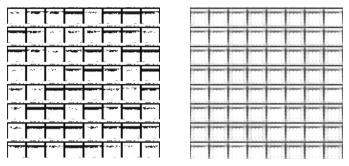

In [24]:
plot_recon(pwa, next(iter(atari_train_loader))[0])

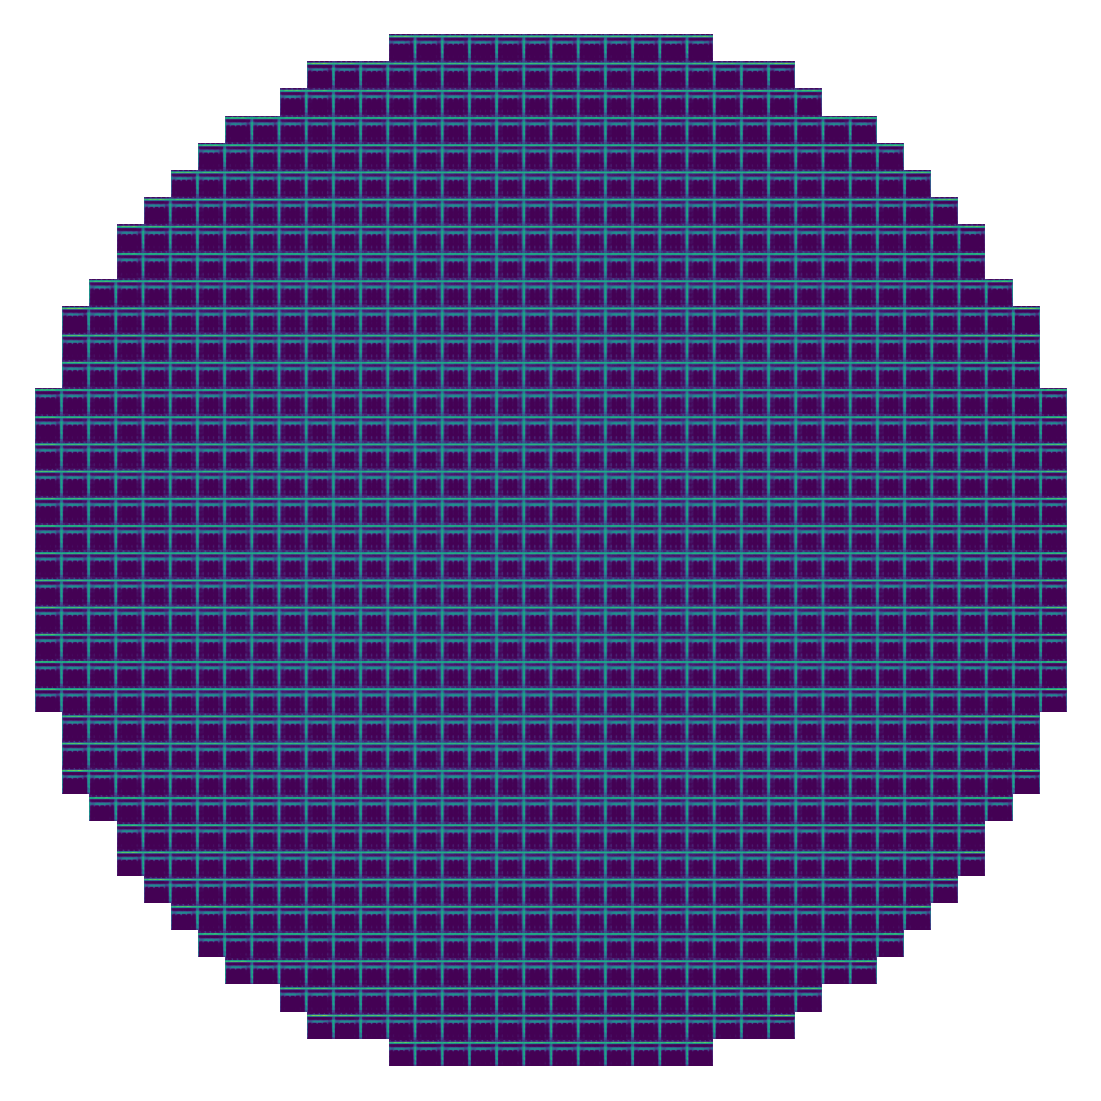

In [238]:
plot_disk(pwa)

### Eval

In [ ]:
encoder = ae.encoder
encoder.eval()

# embed 4 fake images!
fake_image_batch = Tensor(4, 28 * 28)
embeddings = encoder(fake_image_batch)